## Import Libraries

In [ ]:
!pip install -q shap "tab-transformer-pytorch==0.4.2" catboost
import shap


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 10.2 MB/s eta 0:00:00


In [ ]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.feature_selection import mutual_info_classif, RFE
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score
)

import torch
import torch.nn as nn
import torch.optim as optim

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_style('whitegrid')

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Using device:', device)


Using device: cuda


## Load NF-ToN-IoT



In [ ]:
from google.colab import drive
drive.mount('/content/drive')

DATA_PATH = '/content/drive/MyDrive/Dataset/NF-ToN-IoT.parquet'

df = pd.read_parquet(DATA_PATH)
print('Shape:', df.shape)
print('Columns:', list(df.columns))
df.head()


Mounted at /content/drive
Shape: (1157994, 12)
Columns: ['L4_SRC_PORT', 'L4_DST_PORT', 'PROTOCOL', 'L7_PROTO', 'IN_BYTES', 'OUT_BYTES', 'IN_PKTS', 'OUT_PKTS', 'TCP_FLAGS', 'FLOW_DURATION_MILLISECONDS', 'Label', 'Attack']


,L4_SRC_PORT,L4_DST_PORT,PROTOCOL,L7_PROTO,IN_BYTES,OUT_BYTES,IN_PKTS,OUT_PKTS,TCP_FLAGS,FLOW_DURATION_MILLISECONDS,Label,Attack
0,63318,443,6,91.00,181,165,2,1,24,327,0,Benign
1,57442,15600,17,0.00,63,0,1,0,0,0,0,Benign
2,57452,15600,17,0.00,63,0,1,0,0,0,0,Benign
3,138,138,17,10.16,472,0,2,0,0,0,0,Benign
4,51989,15600,17,0.00,63,0,1,0,0,0,0,Benign


## Candidate Feature Pool

Drop identifier/bias columns (`IPV4_SRC_ADDR`, `IPV4_DST_ADDR`, `L4_SRC_PORT`, `L4_DST_PORT`). Everything
that's left (besides the two label columns) goes into Hybrid FS as a candidate -- no manual pruning
beyond removing identifiers.

In [ ]:
ID_COLS = ['IPV4_SRC_ADDR', 'IPV4_DST_ADDR', 'L4_SRC_PORT', 'L4_DST_PORT']
TARGET_COLS = ['Label', 'Attack']

CANDIDATE_FEATURES = [c for c in df.columns if c not in ID_COLS + TARGET_COLS]
print(f'Candidate feature pool ({len(CANDIDATE_FEATURES)}):', CANDIDATE_FEATURES)

X_full = df[CANDIDATE_FEATURES].copy()
X_full.replace([np.inf, -np.inf], np.nan, inplace=True)
X_full.fillna(0, inplace=True)

y_binary_full = df['Label'].astype(int)

target_encoder = LabelEncoder()
y_multi_full = target_encoder.fit_transform(df['Attack'].astype(str))
class_names = target_encoder.classes_
print('\nAttack classes:', list(class_names))


Candidate feature pool (8): ['PROTOCOL', 'L7_PROTO', 'IN_BYTES', 'OUT_BYTES', 'IN_PKTS', 'OUT_PKTS', 'TCP_FLAGS', 'FLOW_DURATION_MILLISECONDS']

Attack classes: ['Benign', 'backdoor', 'ddos', 'dos', 'injection', 'mitm', 'password', 'ransomware', 'scanning', 'xss']


## Hybrid Feature Selection


In [ ]:
def run_hybrid_feature_selection(X_train_scaled, y_train, feature_names, n_select,
                                   fs_sample_n=20000, random_state=42):
    """Filter (Mutual Information) + Embedded (XGBoost importance) + Wrapper (RFE) + SHAP,
    combined with Borda-count (average-rank) aggregation -- identical methodology to your
    TON_IoT notebook's Hybrid FS section, just parameterized for reuse across """
    X_df = pd.DataFrame(X_train_scaled, columns=feature_names)

    n = min(fs_sample_n, len(X_df))
    rng = np.random.RandomState(random_state)
    idx = rng.choice(len(X_df), size=n, replace=False)
    X_s, y_s = X_df.iloc[idx], y_train[idx]

    # 1. Filter -- Mutual Information
    mi_scores = mutual_info_classif(X_s, y_s, random_state=random_state)
    mi_rank = pd.Series(mi_scores, index=feature_names).rank(ascending=False)

    # 2. Embedded -- XGBoost feature importance
    xgb_fs = XGBClassifier(n_estimators=200, max_depth=6, learning_rate=0.1,
                            eval_metric='logloss', random_state=random_state, n_jobs=-1)
    xgb_fs.fit(X_s, y_s)
    imp_rank = pd.Series(xgb_fs.feature_importances_, index=feature_names).rank(ascending=False)

    # 3. Wrapper -- Recursive Feature Elimination
    n_select_capped = min(n_select, len(feature_names) - 1) if len(feature_names) > 1 else len(feature_names)
    rfe = RFE(
        estimator=XGBClassifier(n_estimators=80, max_depth=4, eval_metric='logloss',
                                 random_state=random_state, n_jobs=-1),
        n_features_to_select=max(1, n_select_capped), step=1
    )
    rfe.fit(X_s, y_s)
    rfe_rank = pd.Series(rfe.ranking_, index=feature_names).rank(ascending=True)

    # 4. SHAP -- mean |SHAP value| based ranking (on the same XGBoost probe)
    explainer = shap.TreeExplainer(xgb_fs)
    shap_sample_n = min(2000, len(X_s))
    shap_idx = rng.choice(len(X_s), size=shap_sample_n, replace=False)
    shap_values = explainer.shap_values(X_s.iloc[shap_idx])
    if isinstance(shap_values, list):
        mean_abs_shap = np.mean([np.abs(sv).mean(axis=0) for sv in shap_values], axis=0)
    else:
        mean_abs_shap = np.abs(shap_values).mean(axis=0) if shap_values.ndim == 2 else np.abs(shap_values).mean(axis=(0, 2))
    shap_rank = pd.Series(mean_abs_shap, index=feature_names).rank(ascending=False)

    # Borda-count rank aggregation (average rank across all 4 methods, lower = more important)
    rank_table = pd.DataFrame({
        'MI_Rank': mi_rank, 'XGB_Rank': imp_rank, 'RFE_Rank': rfe_rank, 'SHAP_Rank': shap_rank
    })
    rank_table['Avg_Rank'] = rank_table.mean(axis=1)
    final_ranking = rank_table.sort_values('Avg_Rank')

    selected_features = final_ranking.head(n_select).index.tolist()
    return selected_features, final_ranking


In [ ]:
def evaluate_model(name, model, X_tr, X_te, y_tr, y_te, target_names=None, binary=True, plot=True):
    print('=' * 70)
    print(f'MODEL: {name}')
    print('=' * 70)

    model.fit(X_tr, y_tr)
    y_pred = model.predict(X_te)

    acc = accuracy_score(y_te, y_pred)
    avg = 'binary' if binary else 'weighted'
    prec = precision_score(y_te, y_pred, average=avg, zero_division=0)
    rec = recall_score(y_te, y_pred, average=avg, zero_division=0)
    f1 = f1_score(y_te, y_pred, average=avg, zero_division=0)

    print(f'Accuracy : {acc:.4f}')
    print(f'Precision: {prec:.4f}')
    print(f'Recall   : {rec:.4f}')
    print(f'F1-score : {f1:.4f}')

    auc = np.nan
    if binary and hasattr(model, 'predict_proba'):
        try:
            auc = roc_auc_score(y_te, model.predict_proba(X_te)[:, 1])
            print(f'ROC-AUC  : {auc:.4f}')
        except Exception:
            pass

    print()
    print(classification_report(y_te, y_pred, target_names=target_names, zero_division=0))

    if plot:
        cm = confusion_matrix(y_te, y_pred)
        plt.figure(figsize=(7, 6) if not binary else (5, 4))
        sns.heatmap(cm, annot=(binary or len(np.unique(y_te)) <= 12), fmt='d', cmap='Blues',
                    xticklabels=target_names if target_names is not None else 'auto',
                    yticklabels=target_names if target_names is not None else 'auto')
        plt.title(f'Confusion Matrix -- {name}')
        plt.ylabel('Actual'); plt.xlabel('Predicted')
        if not binary:
            plt.xticks(rotation=45, ha='right')
        plt.tight_layout()
        plt.show()

    return {'model': name, 'Accuracy': acc, 'Precision': prec, 'Recall': rec, 'F1': f1,
            'ROC-AUC': auc, 'fitted_model': model}


def plot_train_val_curves(history, model_name):
    epochs_range = range(1, len(history['train_loss']) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    axes[0].plot(epochs_range, history['train_loss'], label='Train Loss', color='steelblue')
    axes[0].plot(epochs_range, history['val_loss'], label='Val Loss', color='indianred')
    axes[0].set_title(f'{model_name} -- Loss Curve'); axes[0].legend()
    axes[1].plot(epochs_range, history['train_acc'], label='Train Accuracy', color='steelblue')
    axes[1].plot(epochs_range, history['val_acc'], label='Val Accuracy', color='indianred')
    axes[1].set_title(f'{model_name} -- Accuracy Curve'); axes[1].legend()
    plt.suptitle(f'{model_name} -- Training vs Validation', fontsize=13)
    plt.tight_layout()
    plt.show()


### Deep Model Classes (TabTransformer / Autoencoder Classifier / TCN)

In [ ]:
from tab_transformer_pytorch import TabTransformer

class TabTransformerWrapper:
    def __init__(self, n_features, n_classes, dim=32, depth=4, heads=8,
                 epochs=30, batch_size=256, lr=1e-3, val_size=0.10, device='cpu', random_state=42):
        self.device = device
        self.net = TabTransformer(categories=(), num_continuous=n_features, dim=dim, depth=depth,
                                   heads=heads, dim_out=n_classes, mlp_hidden_mults=(4, 2)).to(device)
        self.epochs, self.batch_size, self.lr = epochs, batch_size, lr
        self.val_size, self.random_state = val_size, random_state
        self.history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}

    def _forward(self, X):
        X_t = torch.tensor(X, dtype=torch.float32).to(self.device)
        x_categ = torch.empty((X_t.shape[0], 0), dtype=torch.long).to(self.device)
        return self.net(x_categ, X_t)

    def fit(self, X, y):
        X_tr, X_val, y_tr, y_val = train_test_split(X, y, test_size=self.val_size,
                                                      random_state=self.random_state, stratify=y)
        X_tr_t = torch.tensor(X_tr, dtype=torch.float32).to(self.device)
        y_tr_t = torch.tensor(y_tr, dtype=torch.long).to(self.device)
        y_val_t = torch.tensor(y_val, dtype=torch.long).to(self.device)
        x_categ_tr = torch.empty((X_tr_t.shape[0], 0), dtype=torch.long).to(self.device)
        opt = optim.Adam(self.net.parameters(), lr=self.lr)
        loss_fn = nn.CrossEntropyLoss()
        n = X_tr_t.shape[0]
        for epoch in range(self.epochs):
            self.net.train()
            perm = torch.randperm(n)
            running_loss, correct = 0.0, 0
            for i in range(0, n, self.batch_size):
                idx = perm[i:i + self.batch_size]
                opt.zero_grad()
                logits = self.net(x_categ_tr[idx], X_tr_t[idx])
                loss = loss_fn(logits, y_tr_t[idx])
                loss.backward(); opt.step()
                running_loss += loss.item() * len(idx)
                correct += (logits.argmax(dim=1) == y_tr_t[idx]).sum().item()
            train_loss, train_acc = running_loss / n, correct / n
            self.net.eval()
            with torch.no_grad():
                val_logits = self._forward(X_val)
                val_loss = loss_fn(val_logits, y_val_t).item()
                val_acc = (val_logits.argmax(dim=1) == y_val_t).float().mean().item()
            self.history['train_loss'].append(train_loss); self.history['val_loss'].append(val_loss)
            self.history['train_acc'].append(train_acc); self.history['val_acc'].append(val_acc)
            if (epoch + 1) % 5 == 0 or epoch == 0:
                print(f'  Epoch {epoch+1}/{self.epochs} - train_loss: {train_loss:.4f}, '
                      f'train_acc: {train_acc:.4f}, val_loss: {val_loss:.4f}, val_acc: {val_acc:.4f}')
        return self

    def predict_proba(self, X):
        self.net.eval()
        with torch.no_grad():
            return torch.softmax(self._forward(X), dim=1).cpu().numpy()

    def predict(self, X):
        return np.argmax(self.predict_proba(X), axis=1)


class AEClassifierNet(nn.Module):
    def __init__(self, n_features, n_classes, latent_dim=32, hidden_dim=64):
        super().__init__()
        self.encoder = nn.Sequential(nn.Linear(n_features, hidden_dim), nn.ReLU(),
                                      nn.Linear(hidden_dim, latent_dim), nn.ReLU())
        self.decoder = nn.Sequential(nn.Linear(latent_dim, hidden_dim), nn.ReLU(),
                                      nn.Linear(hidden_dim, n_features))
        self.classifier = nn.Sequential(nn.Linear(latent_dim, hidden_dim), nn.ReLU(),
                                         nn.Dropout(0.2), nn.Linear(hidden_dim, n_classes))

    def forward(self, x):
        z = self.encoder(x)
        return self.classifier(z), self.decoder(z)


class AutoencoderClassifierWrapper:
    def __init__(self, n_features, n_classes, latent_dim=32, hidden_dim=64, epochs=30,
                 batch_size=256, lr=1e-3, val_size=0.10, recon_weight=0.3, device='cpu', random_state=42):
        self.device = device
        self.net = AEClassifierNet(n_features, n_classes, latent_dim, hidden_dim).to(device)
        self.epochs, self.batch_size, self.lr = epochs, batch_size, lr
        self.val_size, self.recon_weight, self.random_state = val_size, recon_weight, random_state
        self.history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}

    def fit(self, X, y):
        X_tr, X_val, y_tr, y_val = train_test_split(X, y, test_size=self.val_size,
                                                      random_state=self.random_state, stratify=y)
        X_tr_t = torch.tensor(X_tr, dtype=torch.float32).to(self.device)
        y_tr_t = torch.tensor(y_tr, dtype=torch.long).to(self.device)
        X_val_t = torch.tensor(X_val, dtype=torch.float32).to(self.device)
        y_val_t = torch.tensor(y_val, dtype=torch.long).to(self.device)
        opt = optim.Adam(self.net.parameters(), lr=self.lr)
        ce, mse = nn.CrossEntropyLoss(), nn.MSELoss()
        n = X_tr_t.shape[0]
        for epoch in range(self.epochs):
            self.net.train()
            perm = torch.randperm(n)
            running_clf_loss, correct = 0.0, 0
            for i in range(0, n, self.batch_size):
                idx = perm[i:i + self.batch_size]
                opt.zero_grad()
                logits, recon = self.net(X_tr_t[idx])
                clf_loss = ce(logits, y_tr_t[idx])
                loss = clf_loss + self.recon_weight * mse(recon, X_tr_t[idx])
                loss.backward(); opt.step()
                running_clf_loss += clf_loss.item() * len(idx)
                correct += (logits.argmax(dim=1) == y_tr_t[idx]).sum().item()
            train_loss, train_acc = running_clf_loss / n, correct / n
            self.net.eval()
            with torch.no_grad():
                val_logits, _ = self.net(X_val_t)
                val_loss = ce(val_logits, y_val_t).item()
                val_acc = (val_logits.argmax(dim=1) == y_val_t).float().mean().item()
            self.history['train_loss'].append(train_loss); self.history['val_loss'].append(val_loss)
            self.history['train_acc'].append(train_acc); self.history['val_acc'].append(val_acc)
            if (epoch + 1) % 5 == 0 or epoch == 0:
                print(f'  Epoch {epoch+1}/{self.epochs} - train_loss: {train_loss:.4f}, '
                      f'train_acc: {train_acc:.4f}, val_loss: {val_loss:.4f}, val_acc: {val_acc:.4f}')
        return self

    def predict_proba(self, X):
        self.net.eval()
        X_t = torch.tensor(X, dtype=torch.float32).to(self.device)
        with torch.no_grad():
            logits, _ = self.net(X_t)
            return torch.softmax(logits, dim=1).cpu().numpy()

    def predict(self, X):
        return np.argmax(self.predict_proba(X), axis=1)


class Chomp1d(nn.Module):
    def __init__(self, chomp_size):
        super().__init__(); self.chomp_size = chomp_size
    def forward(self, x):
        return x[:, :, :-self.chomp_size] if self.chomp_size > 0 else x


class TemporalBlock(nn.Module):
    def __init__(self, n_inputs, n_outputs, kernel_size, dilation, dropout=0.2):
        super().__init__()
        padding = (kernel_size - 1) * dilation
        self.net = nn.Sequential(
            nn.Conv1d(n_inputs, n_outputs, kernel_size, padding=padding, dilation=dilation),
            Chomp1d(padding), nn.ReLU(), nn.Dropout(dropout),
            nn.Conv1d(n_outputs, n_outputs, kernel_size, padding=padding, dilation=dilation),
            Chomp1d(padding), nn.ReLU(), nn.Dropout(dropout))
        self.downsample = nn.Conv1d(n_inputs, n_outputs, 1) if n_inputs != n_outputs else None
        self.relu = nn.ReLU()
    def forward(self, x):
        out = self.net(x)
        res = x if self.downsample is None else self.downsample(x)
        return self.relu(out + res)


class TCNNet(nn.Module):
    def __init__(self, n_classes, channels=(32, 32, 32), kernel_size=3, dropout=0.2):
        super().__init__()
        layers = []
        for i, out_ch in enumerate(channels):
            in_ch = 1 if i == 0 else channels[i - 1]
            layers.append(TemporalBlock(in_ch, out_ch, kernel_size, dilation=2 ** i, dropout=dropout))
        self.tcn = nn.Sequential(*layers)
        self.fc = nn.Linear(channels[-1], n_classes)
    def forward(self, x):
        y = self.tcn(x)
        return self.fc(y.mean(dim=2))


class TCNWrapper:
    def __init__(self, n_features, n_classes, channels=(32, 32, 32), kernel_size=3, dropout=0.2,
                 epochs=30, batch_size=256, lr=1e-3, val_size=0.10, device='cpu', random_state=42):
        self.device = device
        self.net = TCNNet(n_classes, channels=channels, kernel_size=kernel_size, dropout=dropout).to(device)
        self.epochs, self.batch_size, self.lr = epochs, batch_size, lr
        self.val_size, self.random_state = val_size, random_state
        self.history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}

    def _forward(self, X):
        return self.net(torch.tensor(X, dtype=torch.float32).unsqueeze(1).to(self.device))

    def fit(self, X, y):
        X_tr, X_val, y_tr, y_val = train_test_split(X, y, test_size=self.val_size,
                                                      random_state=self.random_state, stratify=y)
        X_tr_t = torch.tensor(X_tr, dtype=torch.float32).unsqueeze(1).to(self.device)
        y_tr_t = torch.tensor(y_tr, dtype=torch.long).to(self.device)
        y_val_t = torch.tensor(y_val, dtype=torch.long).to(self.device)
        opt = optim.Adam(self.net.parameters(), lr=self.lr)
        loss_fn = nn.CrossEntropyLoss()
        n = X_tr_t.shape[0]
        for epoch in range(self.epochs):
            self.net.train()
            perm = torch.randperm(n)
            running_loss, correct = 0.0, 0
            for i in range(0, n, self.batch_size):
                idx = perm[i:i + self.batch_size]
                opt.zero_grad()
                logits = self.net(X_tr_t[idx])
                loss = loss_fn(logits, y_tr_t[idx])
                loss.backward(); opt.step()
                running_loss += loss.item() * len(idx)
                correct += (logits.argmax(dim=1) == y_tr_t[idx]).sum().item()
            train_loss, train_acc = running_loss / n, correct / n
            self.net.eval()
            with torch.no_grad():
                val_logits = self._forward(X_val)
                val_loss = loss_fn(val_logits, y_val_t).item()
                val_acc = (val_logits.argmax(dim=1) == y_val_t).float().mean().item()
            self.history['train_loss'].append(train_loss); self.history['val_loss'].append(val_loss)
            self.history['train_acc'].append(train_acc); self.history['val_acc'].append(val_acc)
            if (epoch + 1) % 5 == 0 or epoch == 0:
                print(f'  Epoch {epoch+1}/{self.epochs} - train_loss: {train_loss:.4f}, '
                      f'train_acc: {train_acc:.4f}, val_loss: {val_loss:.4f}, val_acc: {val_acc:.4f}')
        return self

    def predict_proba(self, X):
        self.net.eval()
        with torch.no_grad():
            return torch.softmax(self._forward(X), dim=1).cpu().numpy()

    def predict(self, X):
        return np.argmax(self.predict_proba(X), axis=1)


In [ ]:
def train_all_7_models(X_train, X_test, y_train, y_test, target_names, binary, n_classes):
    """Trains RF, KNN, XGBoost, CatBoost, TabTransformer, Autoencoder Classifier, TCN
    on the given (already Hybrid-FS-selected + scaled) feature matrix, and returns a
    dict of evaluate_model() results keyed by model name."""
    results = {}

    rf = RandomForestClassifier(n_estimators=50, min_samples_leaf=2, random_state=RANDOM_STATE, n_jobs=-1)
    results['Random Forest'] = evaluate_model('Random Forest', rf, X_train, X_test, y_train, y_test,
                                               target_names=target_names, binary=binary)

    knn = KNeighborsClassifier(n_neighbors=5, n_jobs=-1)
    results['KNN'] = evaluate_model('KNN', knn, X_train, X_test, y_train, y_test,
                                     target_names=target_names, binary=binary)

    xgb = XGBClassifier(n_estimators=100, learning_rate=0.1, max_depth=6,
                         eval_metric='logloss' if binary else 'mlogloss',
                         random_state=RANDOM_STATE, n_jobs=-1)
    results['XGBoost'] = evaluate_model('XGBoost', xgb, X_train, X_test, y_train, y_test,
                                         target_names=target_names, binary=binary)

    cat = CatBoostClassifier(iterations=200, learning_rate=0.1, depth=6, verbose=0, random_state=RANDOM_STATE)
    results['CatBoost'] = evaluate_model('CatBoost', cat, X_train, X_test, y_train, y_test,
                                          target_names=target_names, binary=binary)

    tt = TabTransformerWrapper(n_features=X_train.shape[1], n_classes=n_classes, device=device)
    results['TabTransformer'] = evaluate_model('TabTransformer', tt, X_train, X_test, y_train, y_test,
                                                target_names=target_names, binary=binary)
    plot_train_val_curves(tt.history, 'TabTransformer')

    ae = AutoencoderClassifierWrapper(n_features=X_train.shape[1], n_classes=n_classes, device=device)
    results['Autoencoder Classifier'] = evaluate_model('Autoencoder Classifier', ae, X_train, X_test,
                                                        y_train, y_test, target_names=target_names, binary=binary)
    plot_train_val_curves(ae.history, 'Autoencoder Classifier')

    tcn = TCNWrapper(n_features=X_train.shape[1], n_classes=n_classes, device=device)
    results['TCN'] = evaluate_model('TCN', tcn, X_train, X_test, y_train, y_test,
                                     target_names=target_names, binary=binary)
    plot_train_val_curves(tcn.history, 'TCN')

    return results


# Classification (Normal vs Attack)

`split -> scale -> Hybrid FS -> 7 models`

### Train-Test Split (80:20, stratified)

In [ ]:
X_train_raw_bin, X_test_bin_df, y_train_raw_bin, y_test_bin = train_test_split(
    X_full, y_binary_full, test_size=0.20, random_state=RANDOM_STATE, stratify=y_binary_full
)
print(f'Train: {X_train_raw_bin.shape}   Test (untouched): {X_test_bin_df.shape}')


Train: (926395, 8)   Test (untouched): (231599, 8)


### Scale (fit on train only)


In [ ]:
scaler_bin = StandardScaler()
X_train_scaled_bin = scaler_bin.fit_transform(X_train_raw_bin.values)
X_test_scaled_bin = scaler_bin.transform(X_test_bin_df.values)
y_train_bin = y_train_raw_bin.values
print(f'X_train_scaled: {X_train_scaled_bin.shape}   X_test_scaled: {X_test_scaled_bin.shape}')


X_train_scaled: (926395, 8)   X_test_scaled: (231599, 8)


### Hybrid Feature Selection

In [ ]:
N_SELECT_BIN = 6  # out of 8 candidate features -- adjust if you want a different cut

selected_features_bin, ranking_bin = run_hybrid_feature_selection(
    X_train_scaled_bin, y_train_bin, CANDIDATE_FEATURES, n_select=N_SELECT_BIN
)

print('Selected features (binary):', selected_features_bin)
ranking_bin


Selected features (binary): ['OUT_BYTES', 'IN_BYTES', 'IN_PKTS', 'TCP_FLAGS', 'L7_PROTO', 'PROTOCOL']


,MI_Rank,XGB_Rank,RFE_Rank,SHAP_Rank,Avg_Rank
OUT_BYTES,1.0,1.0,3.5,1.0,1.625
IN_BYTES,2.0,6.0,3.5,2.0,3.375
IN_PKTS,4.0,4.0,3.5,3.0,3.625
TCP_FLAGS,3.0,3.0,3.5,6.0,3.875
L7_PROTO,6.0,5.0,3.5,4.0,4.625
PROTOCOL,8.0,2.0,3.5,8.0,5.375
FLOW_DURATION_MILLISECONDS,7.0,7.0,7.0,5.0,6.500
OUT_PKTS,5.0,8.0,8.0,7.0,7.000


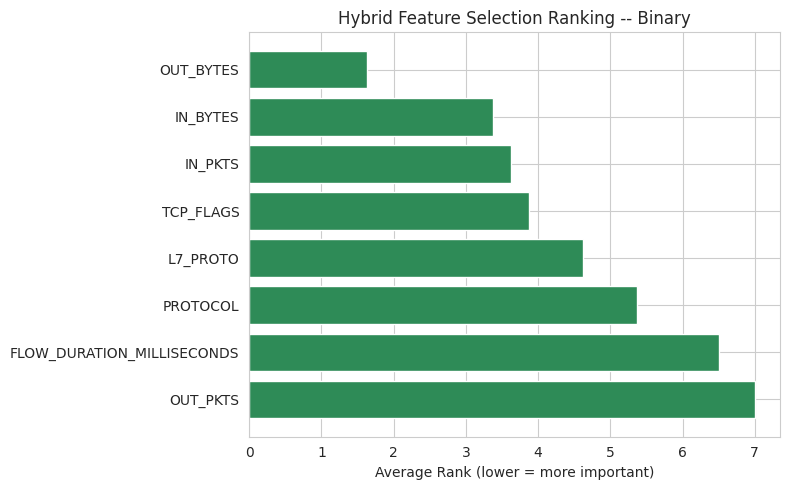

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))
plot_df = ranking_bin.head(len(CANDIDATE_FEATURES)).iloc[::-1]
ax.barh(plot_df.index, plot_df['Avg_Rank'], color='seagreen')
ax.set_xlabel('Average Rank (lower = more important)')
ax.set_title('Hybrid Feature Selection Ranking -- Binary')
plt.tight_layout()
plt.show()


In [ ]:
feat_idx_bin = [CANDIDATE_FEATURES.index(f) for f in selected_features_bin]
X_train_final_bin = X_train_scaled_bin[:, feat_idx_bin]
X_test_final_bin = X_test_scaled_bin[:, feat_idx_bin]
print('Final training matrix (binary):', X_train_final_bin.shape)


Final training matrix (binary): (926395, 6)


### Train All 7 Models

MODEL: Random Forest
Accuracy : 0.9962
Precision: 0.9975
Recall   : 0.9979
F1-score : 0.9977
ROC-AUC  : 0.9996

              precision    recall  f1-score   support

      Normal       0.99      0.99      0.99     39690
      Attack       1.00      1.00      1.00    191909

    accuracy                           1.00    231599
   macro avg       0.99      0.99      0.99    231599
weighted avg       1.00      1.00      1.00    231599



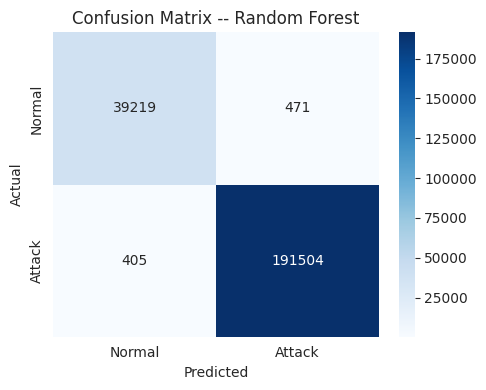

MODEL: KNN
Accuracy : 0.9918
Precision: 0.9920
Recall   : 0.9981
F1-score : 0.9951
ROC-AUC  : 0.9973

              precision    recall  f1-score   support

      Normal       0.99      0.96      0.98     39690
      Attack       0.99      1.00      1.00    191909

    accuracy                           0.99    231599
   macro avg       0.99      0.98      0.99    231599
weighted avg       0.99      0.99      0.99    231599



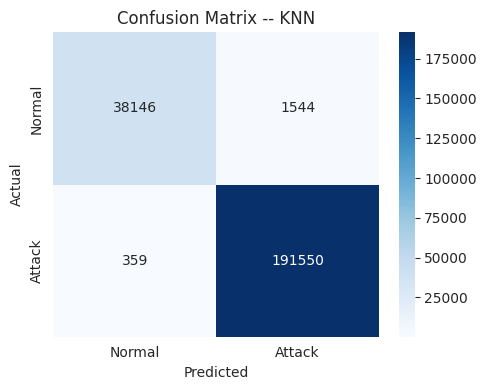

MODEL: XGBoost
Accuracy : 0.9941
Precision: 0.9963
Recall   : 0.9966
F1-score : 0.9964
ROC-AUC  : 0.9994

              precision    recall  f1-score   support

      Normal       0.98      0.98      0.98     39690
      Attack       1.00      1.00      1.00    191909

    accuracy                           0.99    231599
   macro avg       0.99      0.99      0.99    231599
weighted avg       0.99      0.99      0.99    231599



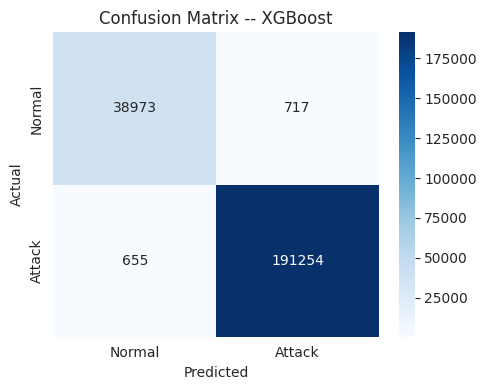

MODEL: CatBoost
Accuracy : 0.9938
Precision: 0.9958
Recall   : 0.9967
F1-score : 0.9963
ROC-AUC  : 0.9993

              precision    recall  f1-score   support

      Normal       0.98      0.98      0.98     39690
      Attack       1.00      1.00      1.00    191909

    accuracy                           0.99    231599
   macro avg       0.99      0.99      0.99    231599
weighted avg       0.99      0.99      0.99    231599



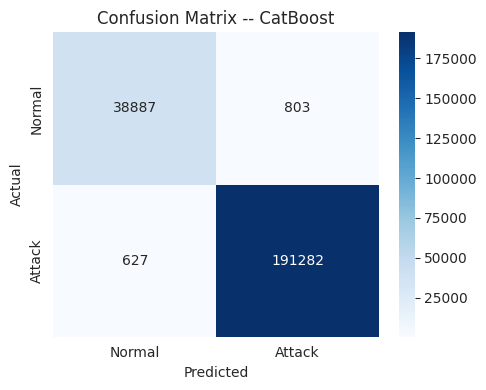

MODEL: TabTransformer
  Epoch 1/30 - train_loss: 0.3408, train_acc: 0.8532, val_loss: 0.3088, val_acc: 0.9016
  Epoch 5/30 - train_loss: 0.2307, train_acc: 0.9241, val_loss: 0.2252, val_acc: 0.9247
  Epoch 10/30 - train_loss: 0.2141, train_acc: 0.9285, val_loss: 0.2089, val_acc: 0.9303
  Epoch 15/30 - train_loss: 0.2046, train_acc: 0.9303, val_loss: 0.2016, val_acc: 0.9277
  Epoch 20/30 - train_loss: 0.1874, train_acc: 0.9382, val_loss: 0.1794, val_acc: 0.9406
  Epoch 25/30 - train_loss: 0.1735, train_acc: 0.9428, val_loss: 0.1679, val_acc: 0.9454
  Epoch 30/30 - train_loss: 0.1660, train_acc: 0.9447, val_loss: 0.1667, val_acc: 0.9424
Accuracy : 0.9418
Precision: 0.9416
Recall   : 0.9913
F1-score : 0.9658
ROC-AUC  : 0.9543

              precision    recall  f1-score   support

      Normal       0.94      0.70      0.81     39690
      Attack       0.94      0.99      0.97    191909

    accuracy                           0.94    231599
   macro avg       0.94      0.85      0.89    2

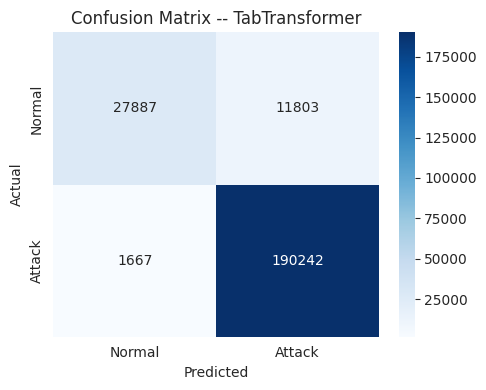

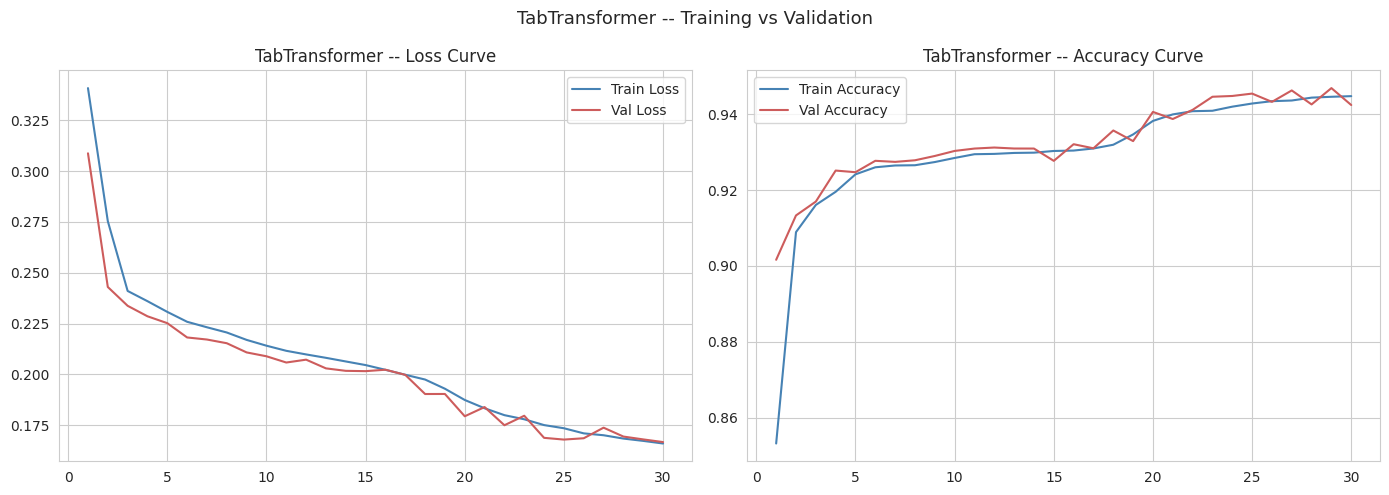

MODEL: Autoencoder Classifier
  Epoch 1/30 - train_loss: 0.2959, train_acc: 0.8847, val_loss: 0.2253, val_acc: 0.9218
  Epoch 5/30 - train_loss: 0.1872, train_acc: 0.9365, val_loss: 0.1719, val_acc: 0.9417
  Epoch 10/30 - train_loss: 0.1577, train_acc: 0.9495, val_loss: 0.1460, val_acc: 0.9541
  Epoch 15/30 - train_loss: 0.1374, train_acc: 0.9529, val_loss: 0.1271, val_acc: 0.9569
  Epoch 20/30 - train_loss: 0.1220, train_acc: 0.9568, val_loss: 0.1111, val_acc: 0.9621
  Epoch 25/30 - train_loss: 0.1139, train_acc: 0.9587, val_loss: 0.1025, val_acc: 0.9615
  Epoch 30/30 - train_loss: 0.1089, train_acc: 0.9602, val_loss: 0.0985, val_acc: 0.9618
Accuracy : 0.9619
Precision: 0.9667
Recall   : 0.9880
F1-score : 0.9772
ROC-AUC  : 0.9861

              precision    recall  f1-score   support

      Normal       0.94      0.84      0.88     39690
      Attack       0.97      0.99      0.98    191909

    accuracy                           0.96    231599
   macro avg       0.95      0.91      0

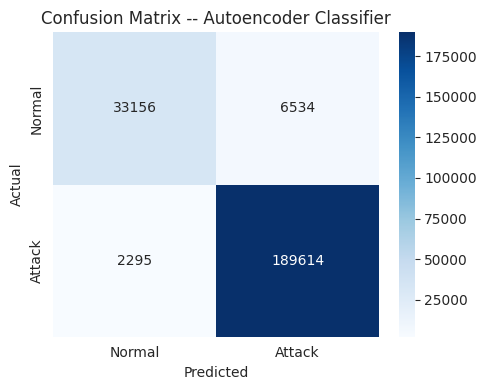

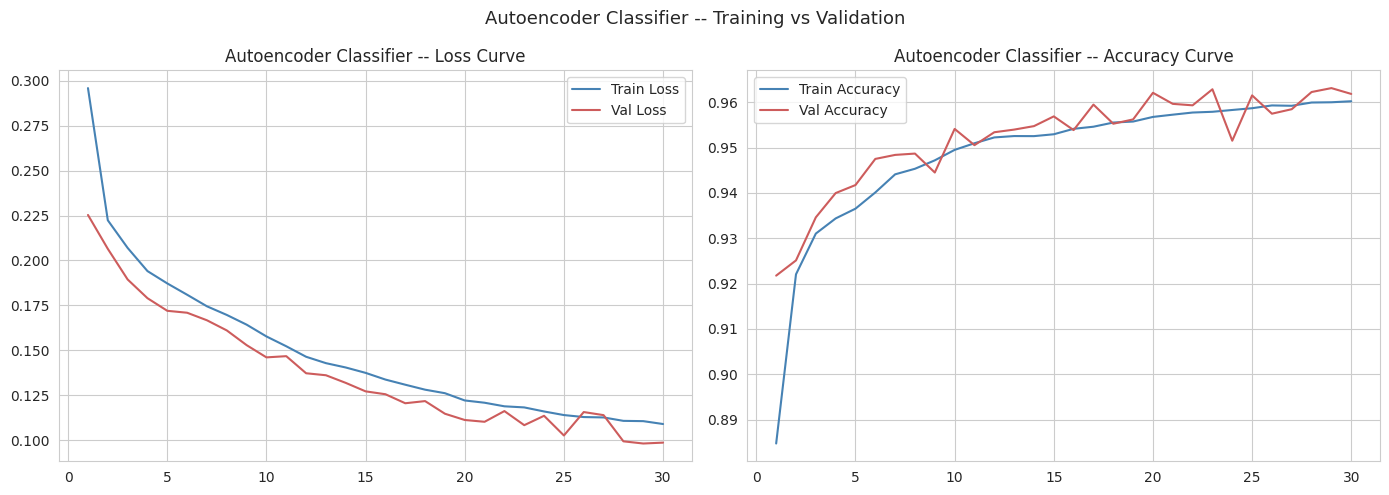

MODEL: TCN
  Epoch 1/30 - train_loss: 0.3002, train_acc: 0.8850, val_loss: 0.2242, val_acc: 0.9293
  Epoch 5/30 - train_loss: 0.2021, train_acc: 0.9335, val_loss: 0.1759, val_acc: 0.9401
  Epoch 10/30 - train_loss: 0.1787, train_acc: 0.9393, val_loss: 0.1624, val_acc: 0.9425
  Epoch 15/30 - train_loss: 0.1676, train_acc: 0.9408, val_loss: 0.1481, val_acc: 0.9437
  Epoch 20/30 - train_loss: 0.1588, train_acc: 0.9460, val_loss: 0.1419, val_acc: 0.9512
  Epoch 25/30 - train_loss: 0.1436, train_acc: 0.9525, val_loss: 0.1366, val_acc: 0.9565
  Epoch 30/30 - train_loss: 0.1350, train_acc: 0.9549, val_loss: 0.1331, val_acc: 0.9574
Accuracy : 0.9573
Precision: 0.9606
Recall   : 0.9890
F1-score : 0.9746
ROC-AUC  : 0.9702

              precision    recall  f1-score   support

      Normal       0.94      0.80      0.87     39690
      Attack       0.96      0.99      0.97    191909

    accuracy                           0.96    231599
   macro avg       0.95      0.90      0.92    231599
weigh

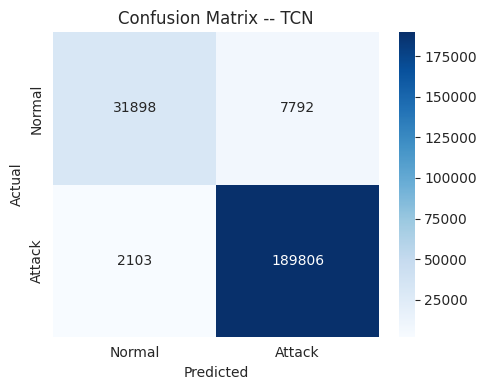

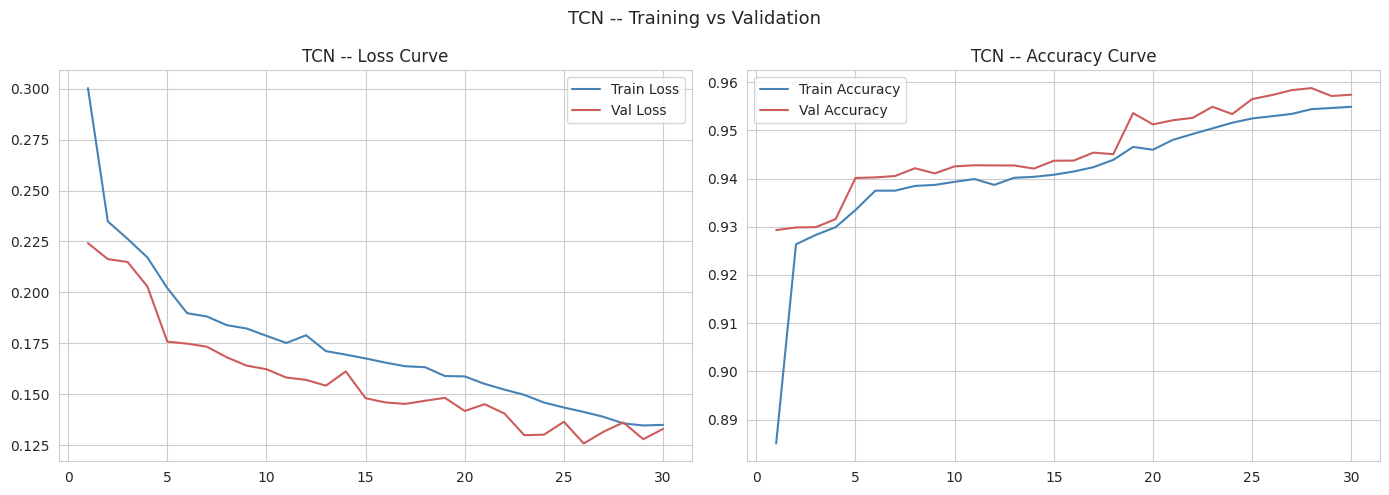

In [ ]:
results_bin = train_all_7_models(
    X_train_final_bin, X_test_final_bin, y_train_bin, y_test_bin.values,
    target_names=['Normal', 'Attack'], binary=True, n_classes=2
)
